## 1. Imports and configuration

In [21]:
import random, math, time, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)

Device: cuda
GPU: Tesla T4
PyTorch: 2.11.0+cu128


## 2. Locate cached frames and configure outputs

In [22]:
# Reuse frames already extracted by the previous notebook.
FRAME_DIR = Path("/kaggle/working/custom_gan_training_256px/real_train_frames")
# If this notebook is started in a fresh session, also look for attached notebook outputs.
if not FRAME_DIR.exists():
    for search_root in (Path("/kaggle/input"), Path("/kaggle/working")):
        if search_root.exists():
            matches = list(search_root.rglob("real_train_frames"))
            matches = [p for p in matches if p.is_dir() and any(p.glob("real_*.jpg"))]
            if matches:
                FRAME_DIR = matches[0]
                print("Found cached frames at:", FRAME_DIR)
                break

Found cached frames at: /kaggle/working/custom_gan_training/real_train_frames


In [23]:
OUTPUT_DIR = Path("/kaggle/working/gan_image_enhancement_256px")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [24]:
IMAGE_SIZE = 256
BATCH_SIZE = 8
EPOCHS = 100
NUM_WORKERS = 2
LR_G = 1e-4
LR_D = 5e-5
LAMBDA_PIXEL = 20.0
LAMBDA_EDGE = 1.0
LAMBDA_ADV = 0.01
PATIENCE = 8
RESUME_IF_AVAILABLE = True
MIN_DELTA = 0.0001

In [25]:
if not FRAME_DIR.exists():
    raise FileNotFoundError(
        f"Cached frames were not found at {FRAME_DIR}. Run the existing frame-extraction cell once, "
        "or change FRAME_DIR to the directory containing your real_*.jpg files."
    )

image_paths = sorted(FRAME_DIR.glob("real_*.jpg"))
if len(image_paths) < 20:
    raise RuntimeError(f"Only {len(image_paths)} frames found in {FRAME_DIR}; expected at least 20.")

print("Cached frames:", len(image_paths))
print("Output directory:", OUTPUT_DIR)
print("Image size:", IMAGE_SIZE, "Batch size:", BATCH_SIZE)

Cached frames: 916
Output directory: /kaggle/working/gan_image_enhancement_256px
Image size: 256 Batch size: 8


## 3. Split by source-video group

In [26]:
rows = []

for path in image_paths:
    parts = path.stem.split("_")
    
    if len(parts) != 3 or parts[0] != "real" or not parts[1].isdigit() or not parts[2].isdigit():
        continue
    rows.append({"path": str(path), "video_group": parts[1], "frame_idx": int(parts[2])})
    
frames = pd.DataFrame(rows)

if frames.empty:
    raise ValueError("Could not parse cached filenames. Expected names like real_000001_00.jpg.")

In [27]:
video_groups = sorted(frames["video_group"].unique())
rng = np.random.default_rng(SEED)
rng.shuffle(video_groups)
val_count = max(1, int(round(0.10 * len(video_groups))))
val_groups = set(video_groups[:val_count])
train_frames = frames[~frames["video_group"].isin(val_groups)].reset_index(drop=True)
val_frames = frames[frames["video_group"].isin(val_groups)].reset_index(drop=True)

assert set(train_frames.video_group).isdisjoint(set(val_frames.video_group))

print(f"Videos/groups: {len(video_groups)} | train frames: {len(train_frames)} | validation frames: {len(val_frames)}")
print("Group leakage check: passed")

Videos/groups: 99 | train frames: 712 | validation frames: 80
Group leakage check: passed


## 4. Dataset images

In [28]:
class Dataset(Dataset):
    def __init__(self, frame_table, training):
        self.frame_table = frame_table.reset_index(drop=True)
        self.training = training

    def __len__(self):
        return len(self.frame_table)

    def __getitem__(self, index):
        path = self.frame_table.iloc[index]["path"]
        with Image.open(path) as image:
            image = image.convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.LANCZOS)
            array = np.asarray(image, dtype=np.float32) / 255.0
        target = torch.from_numpy(array).permute(2, 0, 1).contiguous()

        # Simulate moderate low-resolution/noisy input. Validation degradation is deterministic.
        if self.training:
            scale = random.uniform(0.65, 0.90)
            noise_std = random.uniform(0.0, 0.025)
        else:
            scale = 0.75
            noise_std = 0.0
            
        low_size = max(32, int(round(IMAGE_SIZE * scale)))
        
        degraded = F.interpolate(
            target.unsqueeze(0), size=(low_size, low_size), mode="area"
        )
        
        degraded = F.interpolate(
            degraded, size=(IMAGE_SIZE, IMAGE_SIZE), mode="bicubic", align_corners=False
        ).squeeze(0)
        
        if noise_std:
            generator = torch.randn(degraded.shape, dtype=degraded.dtype)
            degraded = degraded + noise_std * generator
            
        degraded = degraded.clamp(0.0, 1.0)
        
        return degraded, target

In [29]:
train_dataset = Dataset(train_frames, training=True)

val_dataset = Dataset(val_frames, training=False)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda"), drop_last=(len(train_dataset) >= BATCH_SIZE),
    persistent_workers=(NUM_WORKERS > 0),
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
    pin_memory=(device.type == "cuda"),
)

print("Training batches:", len(train_loader), "Validation batches:", len(val_loader))

Training batches: 89 Validation batches: 10


## 5. Define a residual restoration generator and patch discriminator

In [30]:
class ResidualBlock(nn.Module):
    def __init__(self, channels=48):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(channels, channels, 3, 1, 1),
            nn.BatchNorm2d(channels),
            nn.PReLU(channels),
            nn.Conv2d(channels, channels, 3, 1, 1),
            nn.BatchNorm2d(channels),
        )
        
    def forward(self, x):
        return x + 0.2 * self.block(x)

In [31]:
class EnhancementGenerator(nn.Module):
    def __init__(self, channels=48, blocks=6):
        super().__init__()
        self.head = nn.Sequential(nn.Conv2d(3, channels, 9, 1, 4), nn.PReLU(channels))
        self.body = nn.Sequential(*[ResidualBlock(channels) for _ in range(blocks)])
        self.body_tail = nn.Sequential(nn.Conv2d(channels, channels, 3, 1, 1), nn.BatchNorm2d(channels))
        self.output = nn.Conv2d(channels, 3, 9, 1, 4)
        
    def forward(self, x):
        features = self.head(x)
        refined = features + self.body_tail(self.body(features))
        # Residual prediction keeps structure and limits unstable color shifts.
        return (x + 0.25 * torch.tanh(self.output(refined))).clamp(0.0, 1.0)

In [32]:
class PatchDiscriminator(nn.Module):
    def __init__(self, base=32):
        super().__init__()
        layers = []
        in_ch = 3
        for out_ch, stride in [(base, 2), (base*2, 2), (base*4, 2), (base*4, 1)]:
            layers += [nn.Conv2d(in_ch, out_ch, 4, stride, 1)]
            if out_ch != base:
                layers += [nn.BatchNorm2d(out_ch)]
            layers += [nn.LeakyReLU(0.2, inplace=True)]
            in_ch = out_ch
        layers += [nn.Conv2d(in_ch, 1, 3, 1, 1)]
        self.net = nn.Sequential(*layers)
        
    def forward(self, x):
        return self.net(x)

In [33]:
G = EnhancementGenerator().to(device)
D = PatchDiscriminator().to(device)
print("Generator parameters:", sum(p.numel() for p in G.parameters()))
print("Discriminator parameters:", sum(p.numel() for p in D.parameters()))

Generator parameters: 295155
Discriminator parameters: 429665


## 6. Losses and checkpoint/resume setup

In [34]:
optimizer_G = torch.optim.Adam(G.parameters(), lr=LR_G, betas=(0.9, 0.999))
optimizer_D = torch.optim.Adam(D.parameters(), lr=LR_D, betas=(0.5, 0.999))
pixel_loss = nn.L1Loss()
adv_loss_fn = nn.BCEWithLogitsLoss()

In [35]:
# Fixed Sobel filters for edge preservation.
sobel_x = torch.tensor([[-1,0,1],[-2,0,2],[-1,0,1]], dtype=torch.float32, device=device).view(1,1,3,3)
sobel_y = torch.tensor([[-1,-2,-1],[0,0,0],[1,2,1]], dtype=torch.float32, device=device).view(1,1,3,3)

In [36]:
def edge_loss(pred, target):
    pred_gray = pred.mean(dim=1, keepdim=True)
    target_gray = target.mean(dim=1, keepdim=True)
    px, py = F.conv2d(pred_gray, sobel_x, padding=1), F.conv2d(pred_gray, sobel_y, padding=1)
    tx, ty = F.conv2d(target_gray, sobel_x, padding=1), F.conv2d(target_gray, sobel_y, padding=1)
    return F.l1_loss(px, tx) + F.l1_loss(py, ty)

In [37]:
latest_path = OUTPUT_DIR / "enhancement_latest.pth"
best_path = OUTPUT_DIR / "enhancement_best.pth"
history_path = OUTPUT_DIR / "enhancement_history.csv"
preview_path = OUTPUT_DIR / "enhancement_preview.png"
history = []
start_epoch = 1
best_val = float("inf")
bad_epochs = 0

In [38]:
if RESUME_IF_AVAILABLE and latest_path.exists():
    saved = torch.load(latest_path, map_location=device, weights_only=False)
    
    if saved.get("image_size") != IMAGE_SIZE:
        raise ValueError("Checkpoint image size differs from current IMAGE_SIZE.")
        
    G.load_state_dict(saved["G"])
    D.load_state_dict(saved["D"])
    optimizer_G.load_state_dict(saved["optimizer_G"])
    optimizer_D.load_state_dict(saved["optimizer_D"])
    history = saved.get("history", [])
    start_epoch = int(saved["epoch"]) + 1
    best_val = float(saved.get("best_val", float("inf")))
    bad_epochs = int(saved.get("bad_epochs", 0))
    
    print(f"Resuming from epoch {start_epoch}; best validation L1={best_val:.5f}")
else:
    print("Starting new enhancement model.")

Resuming from epoch 18; best validation L1=0.01493


## 7. Train the enhancement GAN

In [39]:
def psnr(pred, target):
    mse = F.mse_loss(pred, target).clamp_min(1e-10)
    return float((-10.0 * torch.log10(mse)).item())

Epoch 18/100 | batch 1/89 | G=0.5208 D=0.4204
Epoch 18/100 | batch 25/89 | G=0.4931 D=0.4792
Epoch 18/100 | batch 50/89 | G=0.3767 D=0.5413
Epoch 18/100 | batch 75/89 | G=0.4052 D=0.4265
Epoch 18/100 | batch 89/89 | G=0.3914 D=0.6224
Epoch 18/100 | pixel=0.01624 edge=0.11046 adv=1.10283 val_L1=0.01542 | PSNR input=30.65dB output=30.91dB | 1.2 min


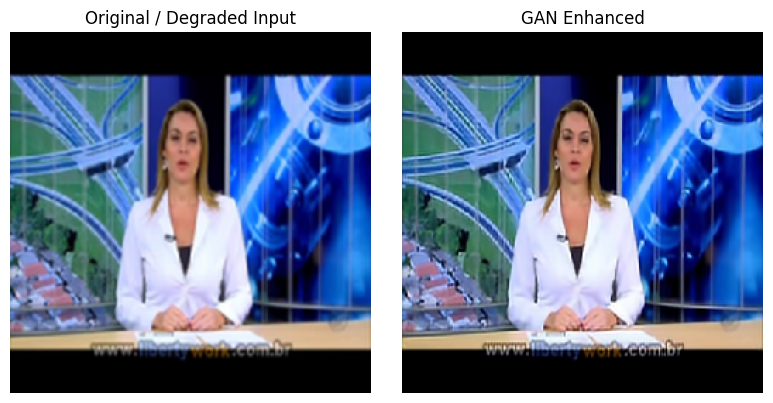

Epoch 19/100 | batch 1/89 | G=0.4066 D=0.7979
Epoch 19/100 | batch 25/89 | G=0.3801 D=0.4268
Epoch 19/100 | batch 50/89 | G=0.4041 D=0.4888
Epoch 19/100 | batch 75/89 | G=0.4837 D=0.5262
Epoch 19/100 | batch 89/89 | G=0.4181 D=0.5021
Epoch 19/100 | pixel=0.01629 edge=0.11096 adv=1.05818 val_L1=0.01541 | PSNR input=30.65dB output=30.94dB | 1.2 min


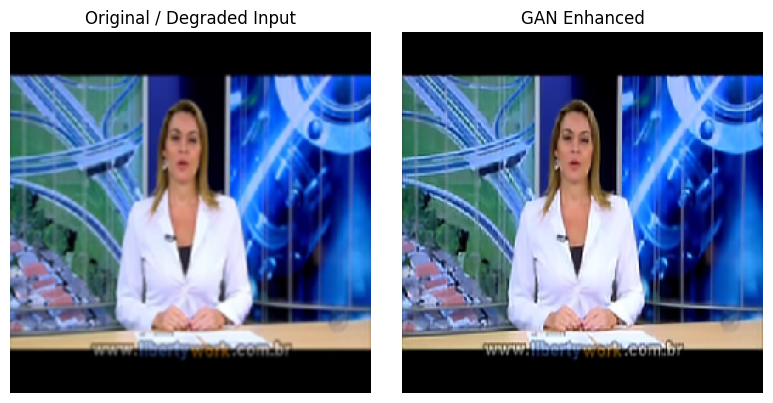

Epoch 20/100 | batch 1/89 | G=0.4242 D=0.6752
Epoch 20/100 | batch 25/89 | G=0.3747 D=0.6799
Epoch 20/100 | batch 50/89 | G=0.4627 D=0.5187
Epoch 20/100 | batch 75/89 | G=0.5052 D=0.3576
Epoch 20/100 | batch 89/89 | G=0.3695 D=0.4147
Epoch 20/100 | pixel=0.01612 edge=0.11017 adv=1.04670 val_L1=0.01562 | PSNR input=30.65dB output=30.68dB | 1.2 min


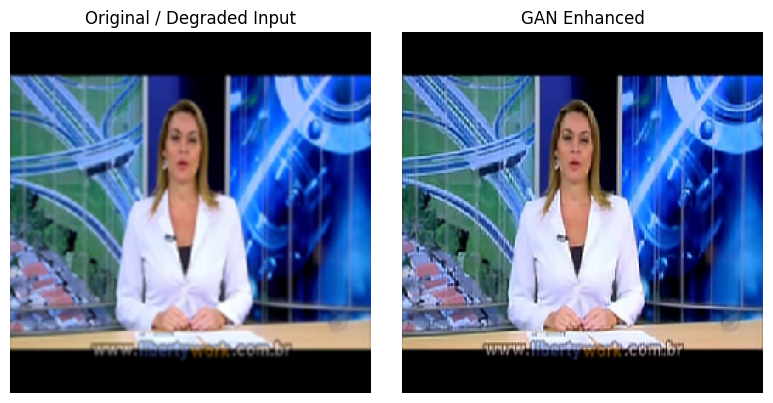

Epoch 21/100 | batch 1/89 | G=0.4898 D=0.5058
Epoch 21/100 | batch 25/89 | G=0.4218 D=0.5992
Epoch 21/100 | batch 50/89 | G=0.5172 D=0.4109
Epoch 21/100 | batch 75/89 | G=0.4459 D=0.7633
Epoch 21/100 | batch 89/89 | G=0.4436 D=0.3804
Epoch 21/100 | pixel=0.01620 edge=0.11061 adv=1.05416 val_L1=0.01494 | PSNR input=30.65dB output=31.07dB | 1.2 min


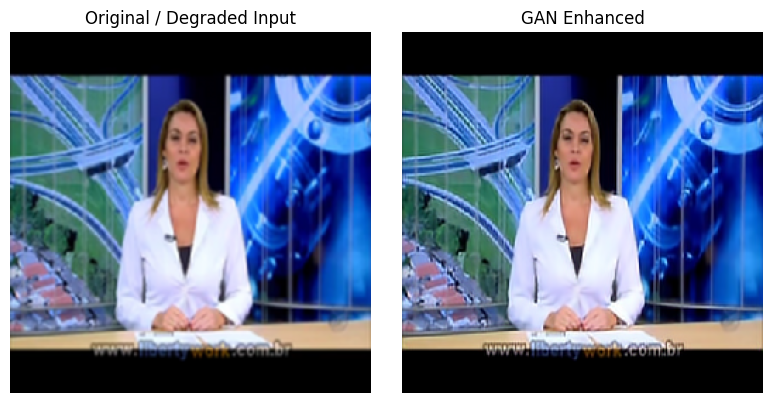

Epoch 22/100 | batch 1/89 | G=0.4383 D=0.5474
Epoch 22/100 | batch 25/89 | G=0.4064 D=0.6528
Epoch 22/100 | batch 50/89 | G=0.4381 D=0.5658
Epoch 22/100 | batch 75/89 | G=0.4064 D=0.5224
Epoch 22/100 | batch 89/89 | G=0.5478 D=0.3739
Epoch 22/100 | pixel=0.01609 edge=0.11037 adv=1.03816 val_L1=0.01494 | PSNR input=30.65dB output=31.12dB | 1.2 min


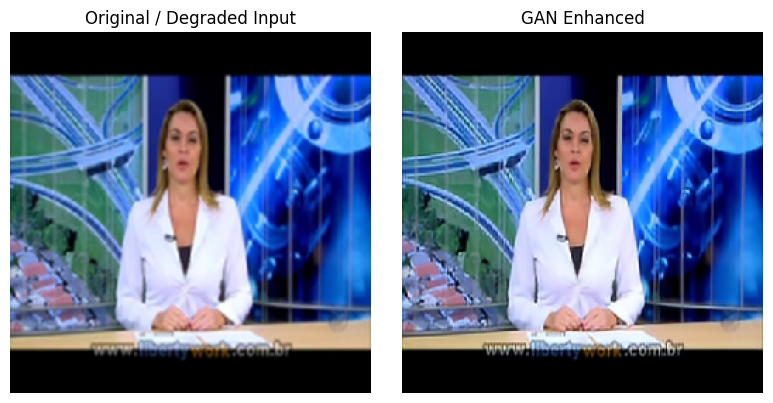

Epoch 23/100 | batch 1/89 | G=0.5234 D=0.4760
Epoch 23/100 | batch 25/89 | G=0.3738 D=0.6179
Epoch 23/100 | batch 50/89 | G=0.4081 D=0.5258
Epoch 23/100 | batch 75/89 | G=0.4649 D=0.3585
Epoch 23/100 | batch 89/89 | G=0.4433 D=0.3386
Epoch 23/100 | pixel=0.01611 edge=0.10970 adv=1.03333 val_L1=0.01506 | PSNR input=30.65dB output=30.98dB | 1.2 min


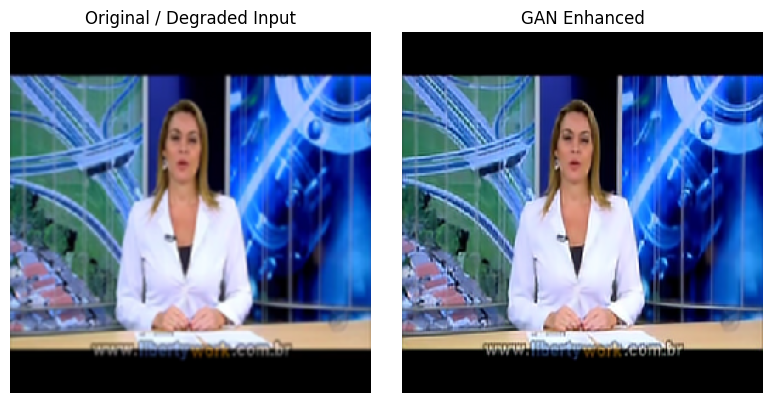

Epoch 24/100 | batch 1/89 | G=0.3921 D=1.0867
Epoch 24/100 | batch 25/89 | G=0.3702 D=0.6146
Epoch 24/100 | batch 50/89 | G=0.4421 D=0.7276
Epoch 24/100 | batch 75/89 | G=0.3361 D=0.4783
Epoch 24/100 | batch 89/89 | G=0.4741 D=0.4944
Epoch 24/100 | pixel=0.01596 edge=0.10964 adv=1.04474 val_L1=0.01495 | PSNR input=30.65dB output=31.19dB | 1.2 min


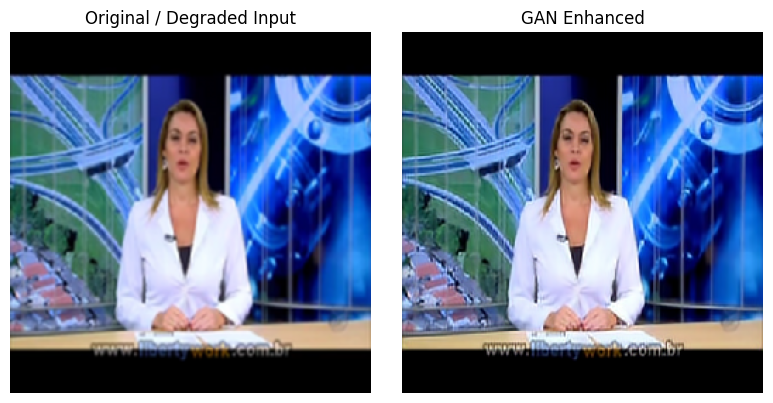

Epoch 25/100 | batch 1/89 | G=0.5628 D=0.3909
Epoch 25/100 | batch 25/89 | G=0.3613 D=0.6981
Epoch 25/100 | batch 50/89 | G=0.3500 D=0.5581
Epoch 25/100 | batch 75/89 | G=0.4433 D=0.3619
Epoch 25/100 | batch 89/89 | G=0.4072 D=0.5474
Epoch 25/100 | pixel=0.01583 edge=0.10826 adv=1.03982 val_L1=0.01512 | PSNR input=30.65dB output=31.04dB | 1.2 min


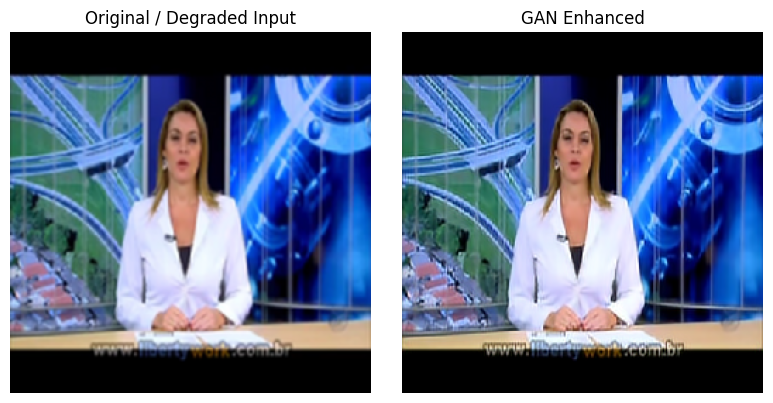

Early stopping after 8 epochs without validation L1 improvement.
Training finished.
Best checkpoint: /kaggle/working/gan_image_enhancement_256px/enhancement_best.pth
Latest resumable checkpoint: /kaggle/working/gan_image_enhancement_256px/enhancement_latest.pth
History: /kaggle/working/gan_image_enhancement_256px/enhancement_history.csv
Latest preview: /kaggle/working/gan_image_enhancement_256px/enhancement_preview.png


In [40]:
for epoch in range(start_epoch, EPOCHS + 1):
    G.train(); D.train()
    running = {"g": 0.0, "d": 0.0, "pixel": 0.0, "edge": 0.0, "adv": 0.0}
    count = 0
    epoch_start = time.time()

    for batch_idx, (degraded, target) in enumerate(train_loader, start=1):
        degraded = degraded.to(device, non_blocking=True)
        target = target.to(device, non_blocking=True)
        bs = degraded.size(0)

        # Update discriminator; real targets are original frames, fake targets are restored frames.
        with torch.no_grad():
            restored_for_d = G(degraded)
            
        optimizer_D.zero_grad(set_to_none=True)
        
        real_logits = D(target)
        
        fake_logits = D(restored_for_d.detach())
        
        d_loss = 0.5 * (
            adv_loss_fn(real_logits, torch.ones_like(real_logits)) +
            adv_loss_fn(fake_logits, torch.zeros_like(fake_logits))
        )
        d_loss.backward()
        optimizer_D.step()

        # Update generator with strong fidelity losses and a small adversarial term.
        optimizer_G.zero_grad(set_to_none=True)
        restored = G(degraded)
        pix = pixel_loss(restored, target)
        edg = edge_loss(restored, target)
        fake_logits_for_g = D(restored)
        adv = adv_loss_fn(fake_logits_for_g, torch.ones_like(fake_logits_for_g))
        g_loss = LAMBDA_PIXEL * pix + LAMBDA_EDGE * edg + LAMBDA_ADV * adv
        g_loss.backward()
        torch.nn.utils.clip_grad_norm_(G.parameters(), max_norm=1.0)
        optimizer_G.step()

        running["g"] += g_loss.item() * bs
        running["d"] += d_loss.item() * bs
        running["pixel"] += pix.item() * bs
        running["edge"] += edg.item() * bs
        running["adv"] += adv.item() * bs
        count += bs

        if batch_idx == 1 or batch_idx % 25 == 0 or batch_idx == len(train_loader):
            print(f"Epoch {epoch}/{EPOCHS} | batch {batch_idx}/{len(train_loader)} | G={g_loss.item():.4f} D={d_loss.item():.4f}")

    G.eval()
    val_l1_sum = 0.0
    val_psnr_in_sum = 0.0
    val_psnr_out_sum = 0.0
    val_count = 0
    first_preview = None
    
    with torch.no_grad():
        for degraded, target in val_loader:
            degraded = degraded.to(device, non_blocking=True)
            target = target.to(device, non_blocking=True)
            restored = G(degraded)
            bs = degraded.size(0)
            val_l1_sum += F.l1_loss(restored, target, reduction="sum").item() / 3.0
            val_psnr_in_sum += psnr(degraded, target) * bs
            val_psnr_out_sum += psnr(restored, target) * bs
            val_count += bs
            if first_preview is None:
                first_preview = (degraded[:4].cpu(), restored[:4].cpu(), target[:4].cpu())

    val_l1 = val_l1_sum / max(val_count * IMAGE_SIZE * IMAGE_SIZE, 1)
    val_psnr_in = val_psnr_in_sum / max(val_count, 1)
    val_psnr_out = val_psnr_out_sum / max(val_count, 1)
    
    row = {
        "epoch": epoch,
        "train_g": running["g"] / max(count, 1),
        "train_d": running["d"] / max(count, 1),
        "train_pixel": running["pixel"] / max(count, 1),
        "train_edge": running["edge"] / max(count, 1),
        "train_adv": running["adv"] / max(count, 1),
        "val_l1": val_l1,
        "val_input_psnr": val_psnr_in,
        "val_output_psnr": val_psnr_out,
        "seconds": time.time() - epoch_start,
    }
    
    history.append(row)
    
    print(
        f"Epoch {epoch}/{EPOCHS} | pixel={row['train_pixel']:.5f} "
        f"edge={row['train_edge']:.5f} adv={row['train_adv']:.5f} "
        f"val_L1={val_l1:.5f} | PSNR input={val_psnr_in:.2f}dB output={val_psnr_out:.2f}dB "
        f"| {row['seconds'] / 60:.1f} min"
    )

    # Save an easy-to-resume full state every epoch.
    improved = val_l1 < best_val - MIN_DELTA
    if improved:
        best_val = val_l1
        bad_epochs = 0
    else:
        bad_epochs += 1
        
    payload = {
        "format": "paired_restoration_gan_v1", "image_size": IMAGE_SIZE, "epoch": epoch,
        "best_val": best_val, "bad_epochs": bad_epochs, "G": G.state_dict(), "D": D.state_dict(),
        "optimizer_G": optimizer_G.state_dict(), "optimizer_D": optimizer_D.state_dict(), "history": history,
    }

    torch.save(payload, latest_path)
    pd.DataFrame(history).to_csv(history_path, index=False)

    if improved:
        torch.save(payload, best_path)
        print("Saved best model:", best_path)

    if first_preview is not None:
        degraded_cpu, restored_cpu, target_cpu = first_preview
    
        # Display only the first validation image
        fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    
        axes[0].imshow(
            degraded_cpu[0].permute(1, 2, 0).clamp(0, 1)
        )
        axes[0].set_title("Original / Degraded Input")
    
        axes[1].imshow(
            restored_cpu[0].permute(1, 2, 0).clamp(0, 1)
        )
        axes[1].set_title("GAN Enhanced")

        for ax in axes:
            ax.axis("off")
    
        plt.tight_layout()
        fig.savefig(preview_path, dpi=130, bbox_inches="tight")
        plt.show()
        plt.close(fig)

    if bad_epochs >= PATIENCE:
        print(f"Early stopping after {PATIENCE} epochs without validation L1 improvement.")
        break

print("Training finished.")
print("Best checkpoint:", best_path)
print("Latest resumable checkpoint:", latest_path)
print("History:", history_path)
print("Latest preview:", preview_path)

## 8. Evaluate the best checkpoint on held-out frames

In [41]:
if not best_path.exists():
    raise FileNotFoundError(f"No best checkpoint found at {best_path}")

best = torch.load(best_path, map_location=device, weights_only=False)
G.load_state_dict(best["G"])
G.eval()

print("Loaded best checkpoint from epoch", best["epoch"])

Loaded best checkpoint from epoch 17


In [42]:
# Compare degraded input, enhanced result, and target on held-out video groups.
all_preview = []

with torch.no_grad():
    for degraded, target in val_loader:
        degraded = degraded.to(device)
        target = target.to(device)
        enhanced = G(degraded)
        for i in range(min(len(degraded), 4 - len(all_preview))):
            all_preview.append((degraded[i].cpu(), enhanced[i].cpu(), target[i].cpu()))
        if len(all_preview) >= 4:
            break

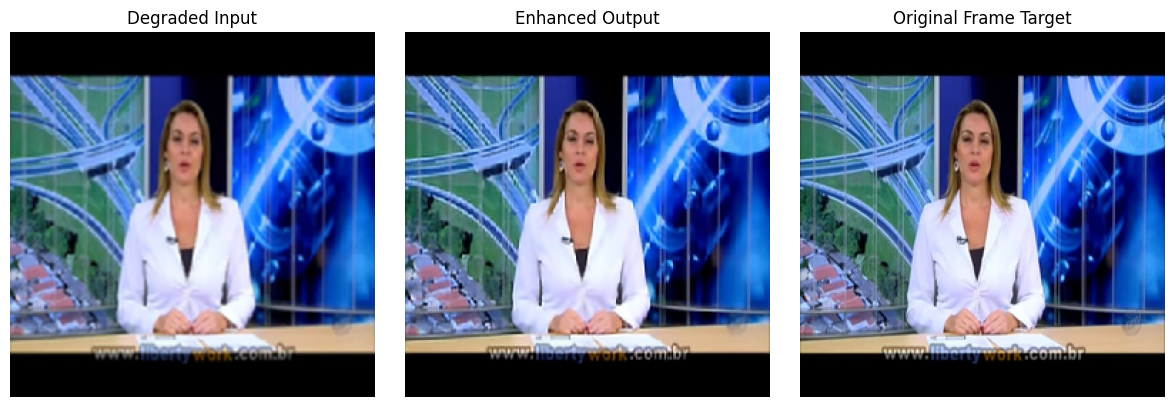

,epoch,train_g,train_d,train_pixel,train_edge,train_adv,val_l1,val_input_psnr,val_output_psnr,seconds
15,16,0.453998,0.516185,0.016511,0.112360,1.141033,0.016817,30.648122,30.586699,69.532066
16,17,0.447684,0.496033,0.016275,0.110818,1.136624,0.014927,30.648122,31.106266,69.693448
17,18,0.446367,0.518977,0.016244,0.110458,1.102828,0.015425,30.648122,30.908023,70.323869
18,19,0.447417,0.534731,0.016294,0.110957,1.058176,0.015406,30.648122,30.936893,69.478662
19,20,0.443120,0.542372,0.016124,0.110169,1.046700,0.015619,30.648122,30.680775,69.725129
20,21,0.445202,0.536403,0.016202,0.110611,1.054163,0.014936,30.648122,31.073947,69.849939
21,22,0.442486,0.551600,0.016087,0.110373,1.038160,0.014938,30.648122,31.116080,69.665101
22,23,0.442285,0.545356,0.016112,0.109704,1.033330,0.015063,30.648122,30.975275,69.700385
23,24,0.439316,0.536448,0.015962,0.109638,1.044738,0.014954,30.648122,31.188383,69.698802
24,25,0.435284,0.529485,0.015832,0.108255,1.039819,0.015121,30.648122,31.041247,69.839581


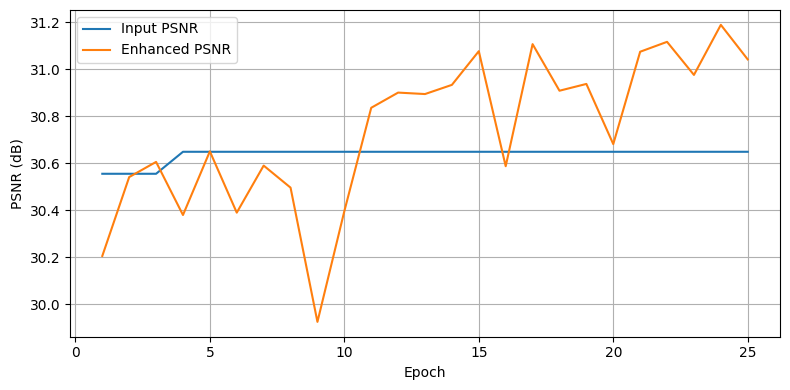

In [43]:
# Display only one sample: Input | Enhanced Output | Original Target

if len(all_preview) > 0:
    inp, out, target = all_preview[0]

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))

    axes[0].imshow(inp.permute(1, 2, 0).clamp(0, 1))
    axes[0].set_title("Degraded Input")

    axes[1].imshow(out.permute(1, 2, 0).clamp(0, 1))
    axes[1].set_title("Enhanced Output")

    axes[2].imshow(target.permute(1, 2, 0).clamp(0, 1))
    axes[2].set_title("Original Frame Target")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No preview images available.")

# Display the latest training metrics
if history_path.exists():
    history_df = pd.read_csv(history_path)
    display(history_df.tail(10))

    plt.figure(figsize=(8, 4))
    plt.plot(history_df["epoch"], history_df["val_input_psnr"],
             label="Input PSNR")
    plt.plot(history_df["epoch"], history_df["val_output_psnr"],
             label="Enhanced PSNR")

    plt.xlabel("Epoch")
    plt.ylabel("PSNR (dB)")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

## 9. Apply the trained enhancer to an image

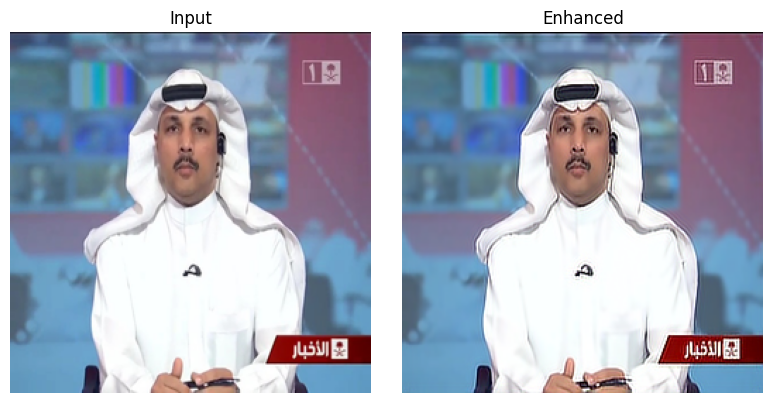

Saved enhanced image: /kaggle/working/gan_image_enhancement_256px/enhanced_example.png


In [44]:
INPUT_IMAGE = str(image_paths[0])  # Change this to the image you want to enhance.
OUTPUT_IMAGE = OUTPUT_DIR / "enhanced_example.png"

with Image.open(INPUT_IMAGE) as image:
    original = image.convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.LANCZOS)
    array = np.asarray(original, dtype=np.float32) / 255.0
    
input_tensor = torch.from_numpy(array).permute(2,0,1).unsqueeze(0).to(device)

with torch.no_grad():
    enhanced_tensor = G(input_tensor).squeeze(0).cpu().clamp(0,1)
    
enhanced_image = Image.fromarray((enhanced_tensor.permute(1,2,0).numpy() * 255).round().astype(np.uint8))
enhanced_image.save(OUTPUT_IMAGE)

fig, axes = plt.subplots(1,2,figsize=(8,4))
axes[0].imshow(original); axes[0].set_title("Input")
axes[1].imshow(enhanced_image); axes[1].set_title("Enhanced")

for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()
print("Saved enhanced image:", OUTPUT_IMAGE)

## 10. Save models

In [45]:
import json
import shutil
from pathlib import Path
import pandas as pd
import torch

ARTIFACT_DIR = Path("/kaggle/working/deepfake_detection_artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Save the best trained enhancement model
best_checkpoint = torch.load(
    best_path, map_location="cpu", weights_only=False
)

torch.save(
    best_checkpoint,
    ARTIFACT_DIR / "gan_enhancement_best.pth"
)

# 2. Save the latest checkpoint for resuming training
if Path(latest_path).exists():
    shutil.copy2(
        latest_path,
        ARTIFACT_DIR / "gan_enhancement_latest.pth"
    )

# 3. Save training history and configuration
pd.DataFrame(history).to_csv(
    ARTIFACT_DIR / "training_history.csv", index=False
)

config = {
    "task": "RGB image enhancement for deepfake detection",
    "image_size": int(IMAGE_SIZE),
    "generator": G.__class__.__name__,
    "discriminator": D.__class__.__name__,
    "batch_size": int(BATCH_SIZE),
    "epochs_configured": int(EPOCHS),
    "best_validation_l1": float(best_checkpoint["best_val"]),
    "checkpoint_format": best_checkpoint.get("format"),
    "pixel_loss_weight": float(LAMBDA_PIXEL),
    "edge_loss_weight": float(LAMBDA_EDGE),
    "adversarial_loss_weight": float(LAMBDA_ADV),
}

with open(ARTIFACT_DIR / "config.json", "w") as f:
    json.dump(config, f, indent=2)

print("Saved enhancement artifacts to:", ARTIFACT_DIR)
print("Files:", sorted(p.name for p in ARTIFACT_DIR.iterdir()))

Saved enhancement artifacts to: /kaggle/working/deepfake_detection_artifacts
Files: ['config.json', 'gan_enhancement_best.pth', 'gan_enhancement_latest.pth', 'training_history.csv']
